In [257]:

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from pandas.plotting import autocorrelation_plot
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing,SimpleExpSmoothing
from pmdarima import auto_arima

In [258]:
df=pd.read_csv(r"C:\Users\PATHWAY\Downloads\mumbai f.csv")
df.head()

,date,price,Address,area,latitude,longitude,Bedrooms,Bathrooms,Balcony,Status,neworold,parking,Furnished_status,Lift,Landmarks,type_of_building,desc,Price_sqft
0,1/1/2000,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35612.082671
1,1/2/2000,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35934.291581
2,1/3/2000,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,NaN,Under Construction,New Property,1.0,NaN,2.0,NaN,Flat,\n \n \n...,32747.933884
3,1/4/2000,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,Ready to Move,New Property,1.0,NaN,3.0,Laxmi Callista,Flat,\n\n\n Welcome ...,29729.729730
4,1/5/2000,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,NaN,NaN,New Property,1.0,Unfurnished,2.0,near uper govind nagar,Flat,\n \n \n...,12385.321101


In [259]:
df['date']=pd.to_datetime(df['date'])

In [260]:
df.set_index('date')

,price,Address,area,latitude,longitude,Bedrooms,Bathrooms,Balcony,Status,neworold,parking,Furnished_status,Lift,Landmarks,type_of_building,desc,Price_sqft
date,,,,,,,,,,,,,,,,,
2000-01-01,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35612.082671
2000-01-02,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35934.291581
2000-01-03,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,NaN,Under Construction,New Property,1.0,NaN,2.0,NaN,Flat,\n \n \n...,32747.933884
2000-01-04,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,Ready to Move,New Property,1.0,NaN,3.0,Laxmi Callista,Flat,\n\n\n Welcome ...,29729.729730
2000-01-05,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,NaN,NaN,New Property,1.0,Unfurnished,2.0,near uper govind nagar,Flat,\n \n \n...,12385.321101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-02-10,19500000.0,"Yari Road, Mumbai - Western Suburbs, Maharashtra",810,19.138320,72.810020,2,2,NaN,Ready to Move,Resale,1.0,Semi-Furnished,NaN,NaN,Flat,\n\n\n This Mu...,24074.074074
2017-02-11,22000000.0,"502., Hari Om Nagar, Mumbai - North Mumbai, Ma...",1400,19.221920,72.854250,3,3,1.0,Ready to Move,Resale,NaN,Unfurnished,NaN,NaN,Flat,\n \n \n...,15714.285714
2017-02-12,20000000.0,"Lokhandwala Complex, Andheri West, Lokhandwala...",750,19.144320,72.824111,2,2,NaN,Ready to Move,Resale,1.0,NaN,1.0,"Lokhandwala Complex, Andheri West",Flat,\n\n\n This Fr...,26666.666667


In [261]:
print('data dimension=',df.shape)

data dimension= (6255, 18)


In [262]:
print(df.columns)

Index(['date', 'price', 'Address', 'area', 'latitude', 'longitude', 'Bedrooms',
       'Bathrooms', 'Balcony', 'Status', 'neworold', 'parking',
       'Furnished_status', 'Lift', 'Landmarks', 'type_of_building', 'desc',
       'Price_sqft'],
      dtype='object')


In [263]:
df.columns=df.columns.str.lower()

In [264]:
print(df.columns)

Index(['date', 'price', 'address', 'area', 'latitude', 'longitude', 'bedrooms',
       'bathrooms', 'balcony', 'status', 'neworold', 'parking',
       'furnished_status', 'lift', 'landmarks', 'type_of_building', 'desc',
       'price_sqft'],
      dtype='object')


In [265]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6255 entries, 0 to 6254
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              6255 non-null   datetime64[ns]
 1   price             6255 non-null   float64       
 2   address           6255 non-null   object        
 3   area              6255 non-null   int64         
 4   latitude          6255 non-null   float64       
 5   longitude         6255 non-null   float64       
 6   bedrooms          6255 non-null   int64         
 7   bathrooms         6255 non-null   int64         
 8   balcony           2376 non-null   float64       
 9   status            5774 non-null   object        
 10  neworold          6255 non-null   object        
 11  parking           2129 non-null   float64       
 12  furnished_status  3600 non-null   object        
 13  lift              1678 non-null   float64       
 14  landmarks         2617 n

In [266]:
print(df.dtypes)

date                datetime64[ns]
price                      float64
address                     object
area                         int64
latitude                   float64
longitude                  float64
bedrooms                     int64
bathrooms                    int64
balcony                    float64
status                      object
neworold                    object
parking                    float64
furnished_status            object
lift                       float64
landmarks                   object
type_of_building            object
desc                        object
price_sqft                 float64
dtype: object


In [267]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,6255,2008-07-24 00:00:00,2000-01-01 00:00:00,2004-04-12 12:00:00,2008-07-24 00:00:00,2012-11-03 12:00:00,2017-02-14 00:00:00,NaN
price,6255.0,26841873.701039,1500000.0,13000000.0,19000000.0,30000000.0,360000000.0,27888310.711244
area,6255.0,1185.62526,503.0,846.5,1000.0,1300.0,8000.0,636.973259
latitude,6255.0,19.156772,18.873713,19.081509,19.147269,19.213054,19.476239,0.109447
longitude,6255.0,72.868642,72.75408,72.83293,72.858019,72.884691,73.197823,0.058614
bedrooms,6255.0,2.452278,2.0,2.0,2.0,3.0,10.0,0.749534
bathrooms,6255.0,2.42558,0.0,2.0,2.0,3.0,10.0,0.762604
balcony,2376.0,2.162879,1.0,1.0,2.0,3.0,8.0,1.221899
parking,2129.0,4.662283,1.0,1.0,1.0,2.0,801.0,35.780057
lift,1678.0,2.448153,0.0,2.0,2.0,3.0,10.0,1.566455


In [268]:
df[df.duplicated(keep=False)]

,date,price,address,area,latitude,longitude,bedrooms,bathrooms,balcony,status,neworold,parking,furnished_status,lift,landmarks,type_of_building,desc,price_sqft


In [269]:
print('Number of duplicates=',df.duplicated().sum())

Number of duplicates= 0


In [270]:
print('missing observations=',df.isna().sum())

missing observations= date                   0
price                  0
address                0
area                   0
latitude               0
longitude              0
bedrooms               0
bathrooms              0
balcony             3879
status               481
neworold               0
parking             4126
furnished_status    2655
lift                4577
landmarks           3638
type_of_building       0
desc                   0
price_sqft             0
dtype: int64


In [271]:
df.isna().mean()

date                0.000000
price               0.000000
address             0.000000
area                0.000000
latitude            0.000000
longitude           0.000000
bedrooms            0.000000
bathrooms           0.000000
balcony             0.620144
status              0.076898
neworold            0.000000
parking             0.659632
furnished_status    0.424460
lift                0.731735
landmarks           0.581615
type_of_building    0.000000
desc                0.000000
price_sqft          0.000000
dtype: float64

# Due to high missingness ,the columns below will be dropped:
parking, 
furnished_status,
landmarks,
status(eventhough the missingness is low)


In [272]:
dd=df.drop(columns=['parking','furnished_status','landmarks','status'])
dd

,date,price,address,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,desc,price_sqft
0,2000-01-01,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,NaN,New Property,2.0,Flat,\n\n\n Right fr...,35612.082671
1,2000-01-02,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,NaN,New Property,2.0,Flat,\n\n\n Right fr...,35934.291581
2,2000-01-03,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,NaN,New Property,2.0,Flat,\n \n \n...,32747.933884
3,2000-01-04,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,New Property,3.0,Flat,\n\n\n Welcome ...,29729.729730
4,2000-01-05,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,NaN,New Property,2.0,Flat,\n \n \n...,12385.321101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6250,2017-02-10,19500000.0,"Yari Road, Mumbai - Western Suburbs, Maharashtra",810,19.138320,72.810020,2,2,NaN,Resale,NaN,Flat,\n\n\n This Mu...,24074.074074
6251,2017-02-11,22000000.0,"502., Hari Om Nagar, Mumbai - North Mumbai, Ma...",1400,19.221920,72.854250,3,3,1.0,Resale,NaN,Flat,\n \n \n...,15714.285714
6252,2017-02-12,20000000.0,"Lokhandwala Complex, Andheri West, Lokhandwala...",750,19.144320,72.824111,2,2,NaN,Resale,1.0,Flat,\n\n\n This Fr...,26666.666667
6253,2017-02-13,11000000.0,"Sion, Mumbai - Central Mumbai, Maharashtra",700,19.047201,72.872225,2,2,NaN,Resale,NaN,Flat,\n,15714.285714


In [273]:
dd.head()

,date,price,address,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,desc,price_sqft
0,2000-01-01,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,NaN,New Property,2.0,Flat,\n\n\n Right fr...,35612.082671
1,2000-01-02,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,NaN,New Property,2.0,Flat,\n\n\n Right fr...,35934.291581
2,2000-01-03,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,NaN,New Property,2.0,Flat,\n \n \n...,32747.933884
3,2000-01-04,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,New Property,3.0,Flat,\n\n\n Welcome ...,29729.729730
4,2000-01-05,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,NaN,New Property,2.0,Flat,\n \n \n...,12385.321101


In [274]:
# Mean imputation will be used for lift,balcony

In [275]:
#balcony
dd['balcony']=dd['balcony'].fillna(dd['balcony'].median())
dd['lift']=dd['lift'].fillna(dd['lift'].median())

In [276]:
dd.isna().any()

date                False
price               False
address             False
area                False
latitude            False
longitude           False
bedrooms            False
bathrooms           False
balcony             False
neworold            False
lift                False
type_of_building    False
desc                False
price_sqft          False
dtype: bool

In [277]:
dd['neworold'].unique()

array(['New Property', 'Resale'], dtype=object)

In [278]:
#Encode the neworold column
from sklearn.preprocessing import LabelEncoder

In [279]:
leb=LabelEncoder()
dd['neworold']=leb.fit_transform(dd['neworold'])

In [280]:
dd.head()

,date,price,address,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,desc,price_sqft
0,2000-01-01,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,2.0,0,2.0,Flat,\n\n\n Right fr...,35612.082671
1,2000-01-02,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,2.0,0,2.0,Flat,\n\n\n Right fr...,35934.291581
2,2000-01-03,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,2.0,0,2.0,Flat,\n \n \n...,32747.933884
3,2000-01-04,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,0,3.0,Flat,\n\n\n Welcome ...,29729.729730
4,2000-01-05,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,2.0,0,2.0,Flat,\n \n \n...,12385.321101


In [281]:
dd['type_of_building'].unique()

array(['Flat', 'Individual House'], dtype=object)

In [282]:
#Encode type_of_building
leb=LabelEncoder()
leb=LabelEncoder()
dd['type_of_building']=leb.fit_transform(dd['type_of_building'])

In [283]:
dd.head()

,date,price,address,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,desc,price_sqft
0,2000-01-01,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629,19.032800,72.896357,2,2,2.0,0,2.0,0,\n\n\n Right fr...,35612.082671
1,2000-01-02,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974,19.032800,72.896357,3,2,2.0,0,2.0,0,\n\n\n Right fr...,35934.291581
2,2000-01-03,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968,19.085600,72.909277,3,3,2.0,0,2.0,0,\n \n \n...,32747.933884
3,2000-01-04,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629,19.155756,72.846862,2,2,2.0,0,3.0,0,\n\n\n Welcome ...,29729.729730
4,2000-01-05,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090,19.177555,72.849887,2,2,2.0,0,2.0,0,\n \n \n...,12385.321101


In [284]:
dd['desc'].unique()

array(['\n\n\n                                Right from Every amenity space is crafted keeping in mind the experience that it will deliver and thus planned with utmost care and perfection. acclaimed architects, interior designers, landscape planners and brands of significance and salience are brought into, to make it a masterpiece.\n                            \nmore\n\n',
       '\n                    \n                    \n                    \n                       Terraform Dwarka has been appointed at a place from where reaching your daily destination is quick and easy. Station, office, mall, market. Reduce your travel and increase your happiness. Now let time fly,you take it easy.\n                    \n                ',
       '\n\n\n                                Welcome to Laxmi Callista, Meaning The Most beutiful. When all your life requirements are at your convenience. Life does appear beautiful.A penchant for a convenient and leisurely lifestyle is now in the offering,

In [285]:
#since desc in unimportant , it must be dropped
dd['address'].unique()

array(['Chembur, Mumbai - Harbour Line, Maharashtra',
       'Ghatkopar East, Mumbai - Central Line, Maharashtra',
       'Plot Number 283, Road Number 3, Jawahar Nagar, Off S. V. Road, Goregaon (West), Mumbai, Maharashtra, India 400104, Goregaon West, Mumbai - North Mumbai, Maharashtra',
       ...,
       'bldg no-137, axiom aven, near ganesh mandir, pant nagar, ghatkopar-east, mum-75, Ghatkopar East, Mumbai - Central Line, Maharashtra',
       '502., Hari Om Nagar, Mumbai - North Mumbai, Maharashtra',
       'Lokhandwala Complex, Andheri West, Lokhandwala Complex, Mumbai - Western Suburbs, Maharashtra'],
      shape=(3632,), dtype=object)

In [286]:
#since desc in unimportant , it must be dropped

In [287]:
fin=dd.drop(columns=['desc','address'])
fin.head()

,date,price,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,price_sqft
0,2000-01-01,22400000.0,629,19.032800,72.896357,2,2,2.0,0,2.0,0,35612.082671
1,2000-01-02,35000000.0,974,19.032800,72.896357,3,2,2.0,0,2.0,0,35934.291581
2,2000-01-03,31700000.0,968,19.085600,72.909277,3,3,2.0,0,2.0,0,32747.933884
3,2000-01-04,18700000.0,629,19.155756,72.846862,2,2,2.0,0,3.0,0,29729.729730
4,2000-01-05,13500000.0,1090,19.177555,72.849887,2,2,2.0,0,2.0,0,12385.321101


Text(0.5, 1.0, 'Price Distribution')

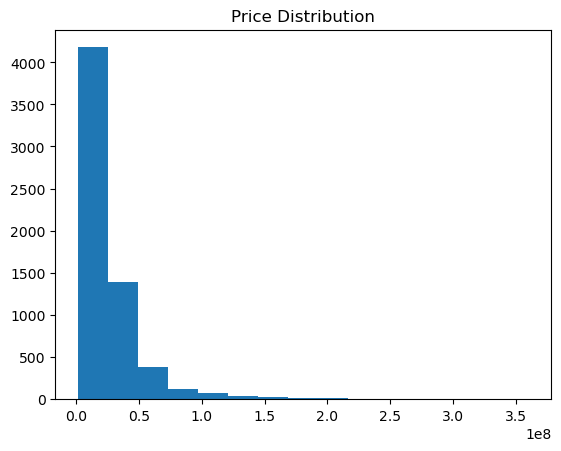

In [288]:
plt.hist(fin['price'],bins=15)
plt.title('Price Distribution')

<Axes: xlabel='price', ylabel='Density'>

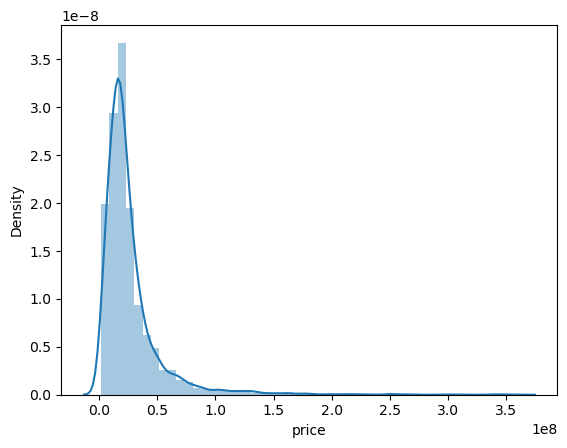

In [289]:
sns.distplot(fin['price'])

Text(0.5, 1.0, 'Relationship Between Price and Bedrooms')

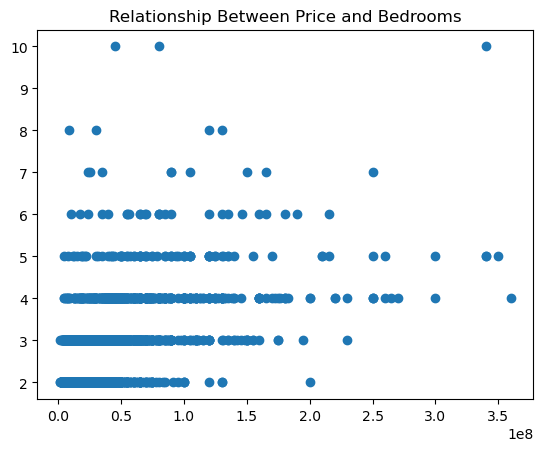

In [290]:
plt.scatter(fin['price'],fin['bedrooms'])
plt.title('Relationship Between Price and Bedrooms')

Text(0.5, 1.0, 'Relationship Between Price and Bathrooms')

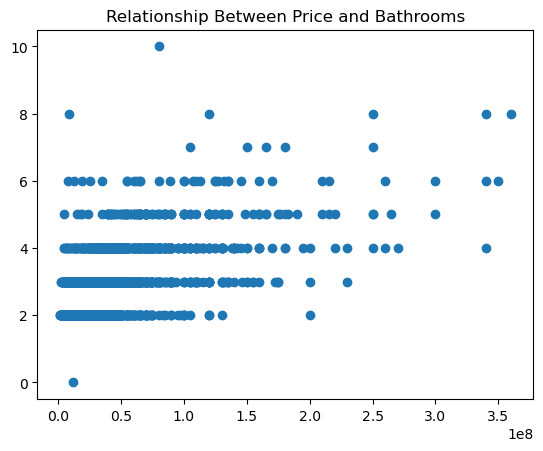

In [291]:
plt.scatter(fin['price'],fin['bathrooms'])
plt.title('Relationship Between Price and Bathrooms')

([<matplotlib.axis.XTick at 0x19b038e51d0>], [Text(1, 0, 'Price')])

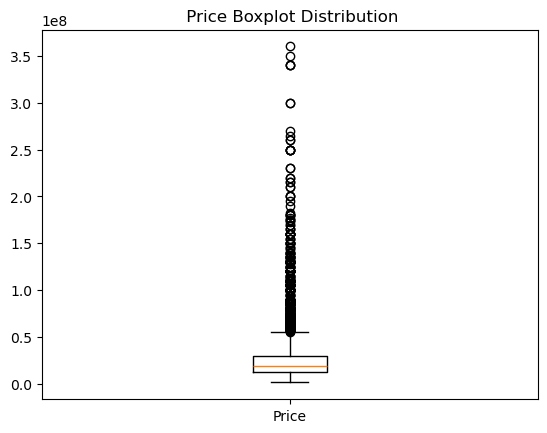

In [292]:
plt.boxplot(fin['price'])
plt.title(' Price Boxplot Distribution')
plt.xticks([1],['Price'])

In [293]:
#IQR
Q3=fin['price'].quantile(.75)
Q1=fin['price'].quantile(.25)
IQR= Q3-Q1

upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
fin['price']=np.where(fin['price']>upper_limit,upper_limit,np.where(fin['price']<lower_limit,lower_limit,fin['price']))


([<matplotlib.axis.XTick at 0x19b039391d0>], [Text(1, 0, 'Price')])

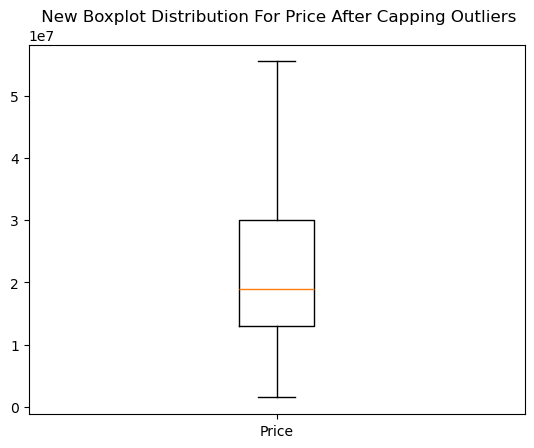

In [294]:
plt.boxplot(fin['price'])
plt.title(' New Boxplot Distribution For Price After Capping Outliers')
plt.xticks([1],['Price'])

<Figure size 1400x1000 with 0 Axes>

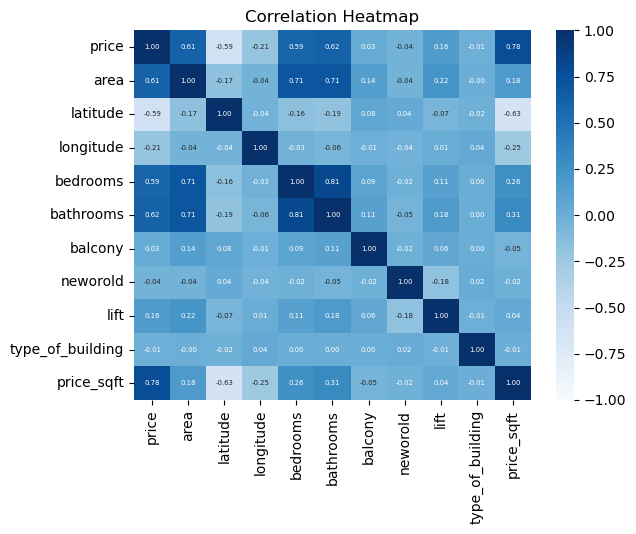

<Figure size 1400x1000 with 0 Axes>

In [295]:
corr=fin.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [296]:
fin['log_price']=np.log(fin['price']).round(2)
fin['bed/bath']=fin['bedrooms']/fin['bathrooms'].round(2)
fin['price_sqft']=fin['price_sqft'].round(2)
fin.head()

,date,price,area,latitude,longitude,bedrooms,bathrooms,balcony,neworold,lift,type_of_building,price_sqft,log_price,bed/bath
0,2000-01-01,22400000.0,629,19.032800,72.896357,2,2,2.0,0,2.0,0,35612.08,16.92,1.0
1,2000-01-02,35000000.0,974,19.032800,72.896357,3,2,2.0,0,2.0,0,35934.29,17.37,1.5
2,2000-01-03,31700000.0,968,19.085600,72.909277,3,3,2.0,0,2.0,0,32747.93,17.27,1.0
3,2000-01-04,18700000.0,629,19.155756,72.846862,2,2,2.0,0,3.0,0,29729.73,16.74,1.0
4,2000-01-05,13500000.0,1090,19.177555,72.849887,2,2,2.0,0,2.0,0,12385.32,16.42,1.0


<Figure size 1400x1000 with 0 Axes>

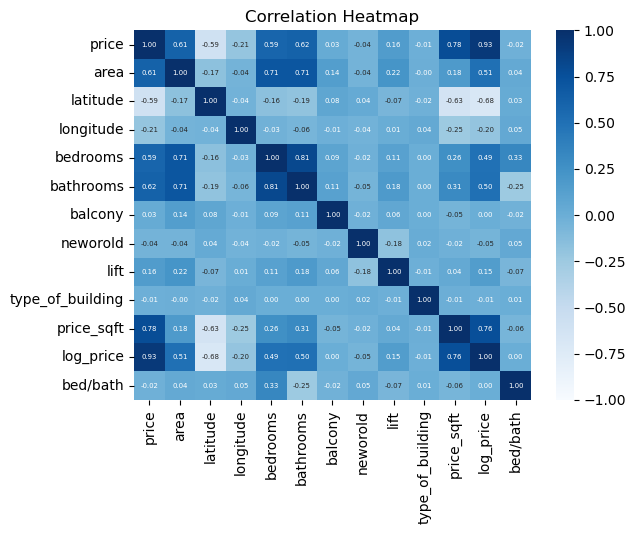

<Figure size 1400x1000 with 0 Axes>

In [297]:
corr=fin.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [298]:
#Defining the Target Variable
x=fin.drop(columns=['price','log_price','date'])
y=fin['log_price']

In [299]:
#Splitting the dataset
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=0)

In [300]:
model=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('lasso',Lasso(alpha=.05,tol=.1,max_iter=100))])

In [301]:
model.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [302]:
# Check for infinities
print(np.isinf(x_test).sum())  # if it's a numpy array
# or if it's a DataFrame:
print(np.isinf(x_test).sum().sum())
print(x_test[np.isinf(x_test).any(axis=1)])  # DataFrame: rows with inf

# Check for absurdly large values too
print(x_test.describe())  # look for huge max values

area                0
latitude            0
longitude           0
bedrooms            0
bathrooms           0
balcony             0
neworold            0
lift                0
type_of_building    0
price_sqft          0
bed/bath            1
dtype: int64
1
      area   latitude  longitude  bedrooms  bathrooms  balcony  neworold  \
3021   812  19.209944  72.830869         2          0      2.0         1   

      lift  type_of_building  price_sqft  bed/bath  
3021   2.0                 0    14778.33       inf  
              area     latitude    longitude     bedrooms    bathrooms  \
count  1251.000000  1251.000000  1251.000000  1251.000000  1251.000000   
mean   1189.415667    19.159829    72.868247     2.469225     2.426059   
std     649.007195     0.111296     0.058247     0.805762     0.767286   
min     503.000000    18.914452    72.768822     2.000000     0.000000   
25%     840.000000    19.081509    72.832508     2.000000     2.000000   
50%    1000.000000    19.149900    72.85

In [303]:
# Check how many zero/problematic values exist
print((fin['bathrooms'] == 0).sum())
print((fin['price'] <= 0).sum())

# Option 1: replace zero bathrooms with NaN before dividing
fin['bed/bath'] = (fin['bedrooms'] / fin['bathrooms'].replace(0, np.nan)).round(2)

# Option 2: drop or impute those rows if there are only a few
fin = fin[fin['bathrooms'] > 0]
fin = fin[fin['price'] > 0]

# Then recompute
fin['log_price'] = np.log(fin['price']).round(2)
fin['bed/bath'] = (fin['bedrooms'] / fin['bathrooms']).round(2)

1
0


In [304]:
x_test = x_test.replace([np.inf, -np.inf], np.nan)
# then impute, e.g.:
x_test = x_test.fillna(x_test.median())

In [305]:
y_pred=model.predict(x_test)
y_pred

array([17.10853338, 16.63198967, 16.5391337 , ..., 16.67886291,
       16.49825382, 16.53194876], shape=(1251,))

In [306]:
model.score(x_test,y_test)

0.9130710164222526

In [307]:
R2=r2_score(y_test,y_pred)
R2

0.9130710164222526

In [308]:
MAE=mean_absolute_error(y_test,y_pred)
MAE

0.1519923985107647

In [309]:
MSE=mean_squared_error(y_test,y_pred)
MSE

0.04093612266886692

In [310]:
RMSE=0.5**MSE
RMSE

0.9720240247453195

In [311]:
ridge_pipeline=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('Ridege',Ridge(alpha=.05,max_iter=100,tol=0.1))])

In [312]:
ridge_pipeline.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [313]:
L2_pred=ridge_pipeline.predict(x_test)
L2_pred

array([17.19004664, 16.6660094 , 16.50417239, ..., 16.78001989,
       16.40283718, 16.64401556], shape=(1251,))

In [314]:
ridge_pipeline.score(x_test,y_test)

0.9518624041731265

In [315]:
MAE_ridge=mean_absolute_error(y_test,L2_pred)
MAE_ridge

0.09370752714829506

In [316]:
MSE_ridge=mean_squared_error(y_test,L2_pred)
MSE_ridge

0.022668693991927315

In [317]:
RMSE_ridge=0.5**MSE_ridge
RMSE_ridge

0.9844100597706077

In [318]:
#model pvalues
X=sm.add_constant(x_train)
pv=sm.OLS(y_train,X).fit()
pv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_price   R-squared:                       0.789
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     1693.
Date:                Tue, 04 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:36:02   Log-Likelihood:                -1344.3
No. Observations:                5004   AIC:                             2713.
Df Residuals:                    4992   BIC:                             2791.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              132.0771      6.336     20.845      0.000     119.655     144.499
area                 0.0003    1.1e-05     26.026      0.000       0.000       0.000
latitude            -2.1284      0.055    -38.489      0.000      -2.237      -2.020
longitude           -1.0346      0.082    -12.620      0.000      -1.195      -0.874
bedrooms             0.2588      0.032      8.010      0.000       0.195       0.322
bathrooms           -0.1301      0.031     -4.184      0.000      -0.191      -0.069
balcony             -0.0057      0.006     -0.937      0.349      -0.018       0.006
neworold            -0.0400      0.014     -2.846      0.004      -0.068      -0.012
lift                 0.0306      0.006      5.514      0.000       0.020       0.042
type_of_building    -0.0439      0.018     -2.475      0.013      -0.079      -0.009
price_sqft        2.368e-05   4.96e-07     47.762      0.000    2.27e-05    2.47e-05
bed/bath            -0.3382      0.082     -4.135      0.000      -0.499      -0.178
==============================================================================
Omnibus:                     1834.573   Durbin-Watson:                   1.992
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            10360.736
Skew:                          -1.653   Prob(JB):                         0.00
Kurtosis:                       9.226   Cond. No.                     3.55e+07
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.55e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [319]:
pv.pvalues

const                1.354280e-92
area                3.835754e-140
latitude            4.710053e-284
longitude            5.750749e-36
bedrooms             1.411379e-15
bathrooms            2.918050e-05
balcony              3.489717e-01
neworold             4.446108e-03
lift                 3.677405e-08
type_of_building     1.335301e-02
price_sqft           0.000000e+00
bed/bath             3.601376e-05
dtype: float64

# Time Series Model

In [320]:
time_data=fin[['date','price']]
time_data.head()

,date,price
0,2000-01-01,22400000.0
1,2000-01-02,35000000.0
2,2000-01-03,31700000.0
3,2000-01-04,18700000.0
4,2000-01-05,13500000.0


Text(0.5, 1.0, 'Price Trend')

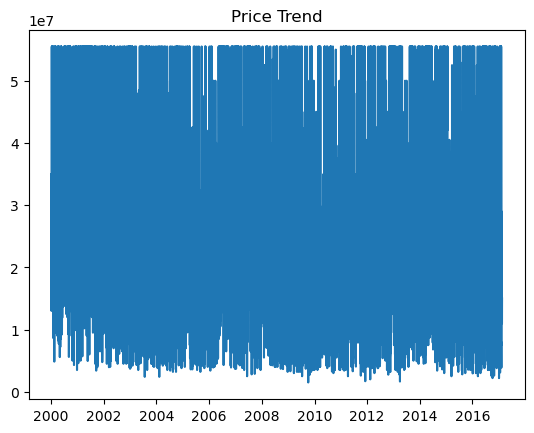

In [321]:
plt.plot(time_data['date'],time_data['price'])
plt.title('Price Trend')

# SImple Moving Average

In [322]:
#forecasting the next 2 tears where 360 days make a year

In [323]:
#Using  4-Month SMA
time_data['SMA_4']=time_data['price'].rolling(window=4).mean()
time_data.head()

,date,price,SMA_4
0,2000-01-01,22400000.0,NaN
1,2000-01-02,35000000.0,NaN
2,2000-01-03,31700000.0,NaN
3,2000-01-04,18700000.0,26950000.0
4,2000-01-05,13500000.0,24725000.0


In [324]:
# forecast the next ten years
last_date=time_data['date'].iloc[-1]
last_SMA=time_data['SMA_4'].iloc[-1]

future_dates=pd.date_range(start=last_date,periods=121,freq='ME')[1:]
forecast=pd.DataFrame({'Forecast':[last_SMA]*120},index=future_dates)
forecast

,Forecast
2017-03-31,17000000.0
2017-04-30,17000000.0
2017-05-31,17000000.0
2017-06-30,17000000.0
2017-07-31,17000000.0
...,...
2026-10-31,17000000.0
2026-11-30,17000000.0
2026-12-31,17000000.0
2027-01-31,17000000.0


In [325]:
actual=time_data['price'].iloc[3:].values
predi=time_data['SMA_4'].dropna().values

In [326]:
Mae=mean_absolute_error(actual,predi)
Mae

9496949.288113901

In [327]:
Mse=mean_squared_error(actual,predi)
Mse

147019297576387.78

In [328]:
Rmse=0.5**Mse
Rmse

0.0

Text(0.5, 1.0, 'Actual Vrs Predicted Outcome')

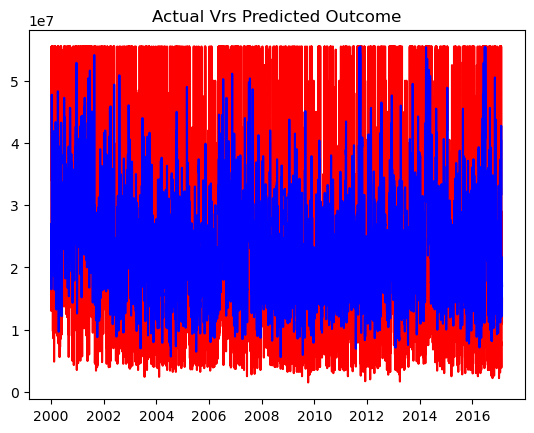

In [329]:
plt.plot(time_data['date'].iloc[3:],actual,label='actual',color='red')
plt.plot(time_data['date'].iloc[3:],predi,label='predicted',color='blue')
plt.title('Actual Vrs Predicted Outcome')

# Simple Exponential Smoothing

In [330]:
SES_model=SimpleExpSmoothing(time_data['price']).fit()

In [331]:
SES_model.summary()

Dep. Variable:,price,No. Observations:,6254
Model:,SimpleExpSmoothing,SSE,1303842393258231296.000
Optimized:,True,AIC,206203.826
Trend:,None,BIC,206217.307
Seasonal:,None,AICC,206203.832
Seasonal Periods:,None,Date:,"Tue, 04 Aug 2026"
Box-Cox:,False,Time:,02:36:06
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.0417740,alpha,True
initial_level,2.24e+07,l.0,False


In [332]:
# Forecast the next 10 years
SES_model.forecast(120)

6254    2.220076e+07
6255    2.220076e+07
6256    2.220076e+07
6257    2.220076e+07
6258    2.220076e+07
            ...     
6369    2.220076e+07
6370    2.220076e+07
6371    2.220076e+07
6372    2.220076e+07
6373    2.220076e+07
Length: 120, dtype: float64